In [30]:
import pandas as pd
df=pd.read_csv("churn.csv")
print(df.shape)
df.head()
df.info()
df[df["TotalCharges"]== " "]
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors = "coerce")
print(df["TotalCharges"].isnull().sum())
df=df.dropna()
df.shape
df = df.drop("customerID",axis=1)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df.shape
df.info()
print(df)
print(df["TotalCharges"])
print(df["Churn"])






(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [31]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import matplotlib.pyplot as plt

In [33]:
import seaborn as sns


In [34]:
print(df["Churn"].value_counts())
print(df["Churn"].mean())

Churn
0    5163
1    1869
Name: count, dtype: int64
0.26578498293515357


In [35]:
df.groupby("Contract")["Churn"].mean()

Contract
Month-to-month    0.427097
One year          0.112772
Two year          0.028487
Name: Churn, dtype: float64

In [36]:
df.groupby("Churn")[["tenure","MonthlyCharges"]].mean()

,tenure,MonthlyCharges
Churn,,
0,37.650010,61.307408
1,17.979133,74.441332


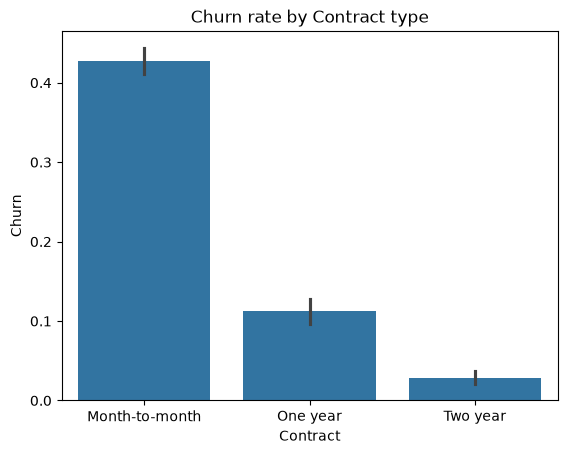

In [37]:
sns.barplot(x="Contract",y="Churn", data = df)
plt.title("Churn rate by Contract type")
plt.show()

In [38]:
df.groupby("InternetService")["Churn"].mean()

InternetService
DSL            0.189983
Fiber optic    0.418928
No             0.074342
Name: Churn, dtype: float64

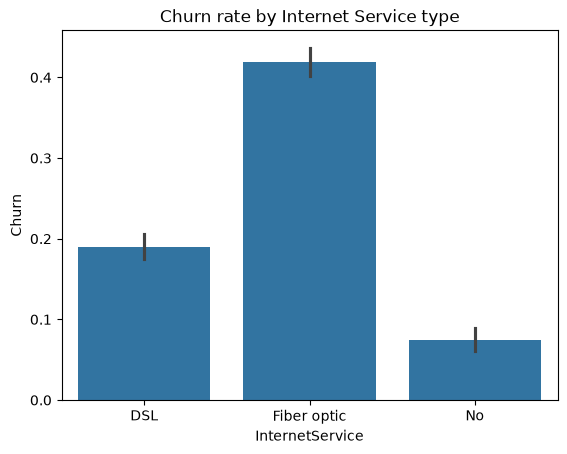

In [39]:
sns.barplot(x="InternetService",y="Churn", data = df)
plt.title("Churn rate by Internet Service type")
plt.show()

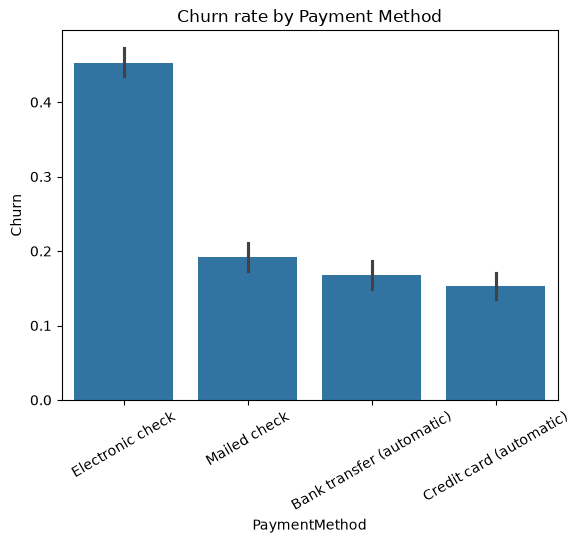

In [40]:
sns.barplot(x="PaymentMethod",y="Churn", data = df)
plt.title("Churn rate by Payment Method")
plt.xticks(rotation=30)
plt.show()

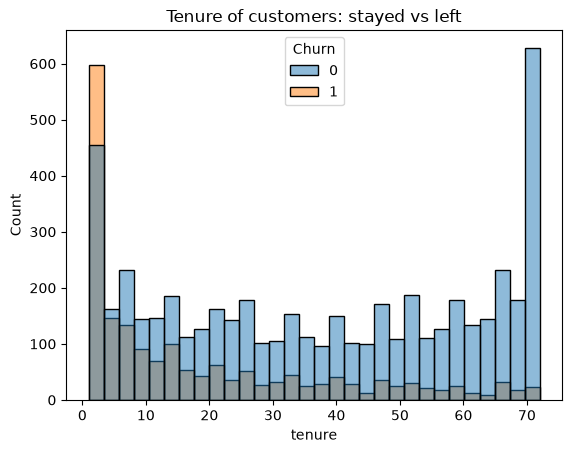

In [41]:
sns.histplot(data = df, x="tenure", hue="Churn", bins=30)
plt.title("Tenure of customers: stayed vs left")
plt.show()

## Key insights
- Overall churn rate is 26.6% (imbalanced data)
- Month-to-month contracts churn at 42.7% vs 2.8% for two-year
- Churners have shorter tenure (18 vs 38 months) and higher bills
- Fiber optic customers churn most (about 41%)
- Churn is concentrated in the first 12 months

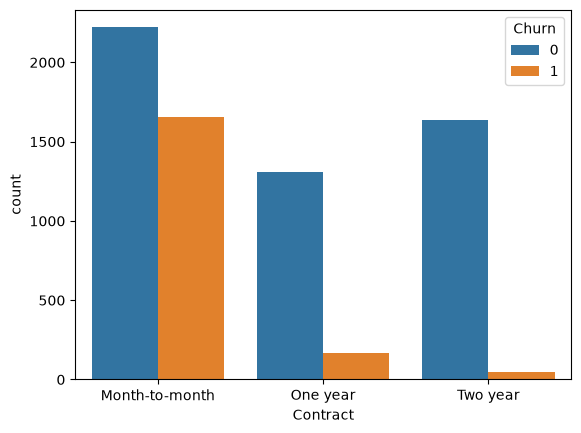

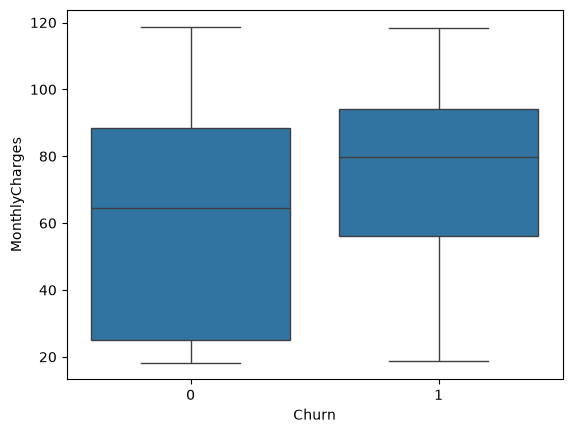

In [42]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.show()

In [43]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"]
X = pd.get_dummies(X, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
lr.fit(X_train, y_train)
print(classification_report(y_test, lr.predict(X_test)))
print("AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]))
print("AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]))

              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

AUC: 0.8349765233911922
AUC: 0.8349765233911922


In [45]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['Churn', 'customerID'], errors='ignore')
y = df['Churn']

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [46]:
print(x.select_dtypes(include="object").columns.tolist())

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\manthuri hrithikesh\AppData\Local\Temp\ipykernel_4576\963047392.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(x.select_dtypes(include="object").columns.tolist())


In [47]:
x = pd.get_dummies(x, drop_first=True)

In [48]:
print(type(y_train), y_train.shape)
print(type(y), y.shape)

<class 'pandas.Series'> (5625,)
<class 'pandas.Series'> (7032,)


In [49]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['Churn', 'customerID'], errors='ignore')
y = df['Churn']

x = pd.get_dummies(x, drop_first=True)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(x_train.dtypes.value_counts())

bool       26
int64       2
float64     2
Name: count, dtype: int64


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf.fit(x_train, y_train)
print(classification_report(y_test, rf.predict(x_test)))
print("RF AUC:", roc_auc_score(y_test, rf.predict_proba(x_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1033
           1       0.56      0.66      0.61       374

    accuracy                           0.77      1407
   macro avg       0.72      0.74      0.72      1407
weighted avg       0.79      0.77      0.78      1407

RF AUC: 0.8209591501829985


In [51]:
print(x_train.select_dtypes(exclude="number").columns.tolist())

['gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


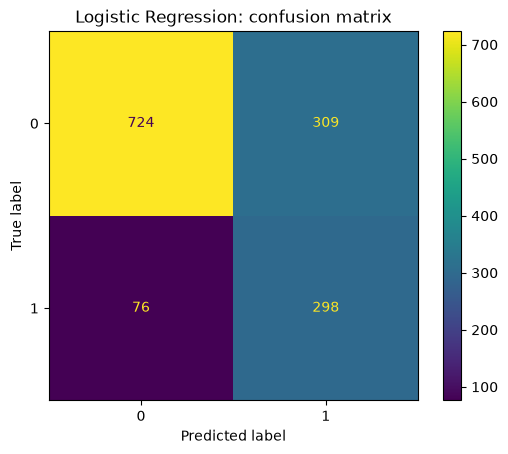

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(lr, x_test, y_test)
plt.title("Logistic Regression: confusion matrix")
plt.show()

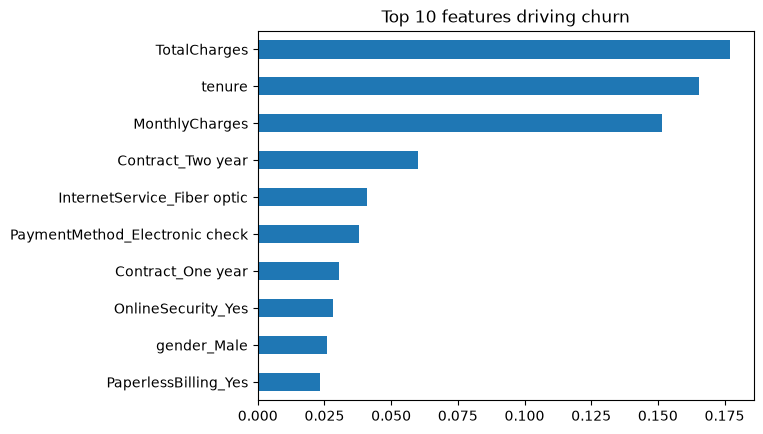

In [53]:
imp = pd.Series(rf.feature_importances_, index=x.columns).nlargest(10)
imp.sort_values().plot(kind="barh")
plt.title("Top 10 features driving churn")
plt.show()

In [54]:
coef = pd.Series(lr[-1].coef_[0], index=x.columns).sort_values()
print(coef.head(5))   # reduce churn
print(coef.tail(5))   # increase churn

tenure               -1.263854
MonthlyCharges       -0.928682
Contract_Two year    -0.638598
Contract_One year    -0.326693
OnlineSecurity_Yes   -0.124312
dtype: float64
MultipleLines_Yes              0.202763
StreamingMovies_Yes            0.252870
StreamingTV_Yes                0.259691
TotalCharges                   0.623279
InternetService_Fiber optic    0.746144
dtype: float64


In [55]:
import joblib
joblib.dump(lr, "churn_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")

['model_columns.pkl']

In [56]:
model = joblib.load("churn_model.pkl")
print(model.predict(x_test[:5]))

[0 1 0 0 0]


•	Best model: Logistic Regression, AUC 0.835, churn recall 0.80
•	Top churn drivers (from the importance and coefficient outputs)
•	One business recommendation

In [57]:
import joblib
joblib.dump(lr, "churn_model.pkl")
joblib.dump(list(x.columns), "model_columns.pkl")

['model_columns.pkl']

In [58]:
   print("Same columns:", list(X.columns) == list(x.columns))
   print("Same test rows:", X_test.shape == x_test.shape)

Same columns: True
Same test rows: True


In [59]:
   import xgboost, shap
   print("xgboost", xgboost.__version__)
   print("shap", shap.__version__)

xgboost 3.4.1
shap 0.52.0


In [60]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

# Churners are fewer, so give them more weight
weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=weight, eval_metric="auc", random_state=42,
)
xgb.fit(x_train, y_train)

xgb_proba = xgb.predict_proba(x_test)[:, 1]
print("XGBoost AUC:", round(roc_auc_score(y_test, xgb_proba), 3))
print(classification_report(y_test, (xgb_proba >= 0.5).astype(int)))

XGBoost AUC: 0.831
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1033
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.80      0.74      0.75      1407



In [61]:
from sklearn.metrics import precision_score, recall_score

lr_proba = lr.predict_proba(x_test)[:, 1]

print("threshold | precision | recall")
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (lr_proba >= t).astype(int)
    print(f"   {t}    |   {precision_score(y_test, pred):.2f}    |  {recall_score(y_test, pred):.2f}")

threshold | precision | recall
   0.3    |   0.41    |  0.93
   0.4    |   0.45    |  0.87
   0.5    |   0.49    |  0.80
   0.6    |   0.54    |  0.72
   0.7    |   0.61    |  0.61


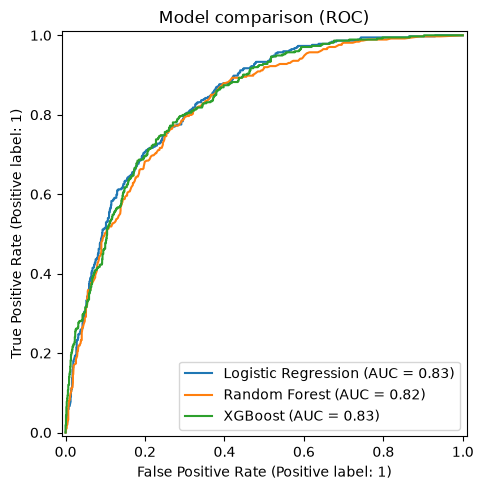

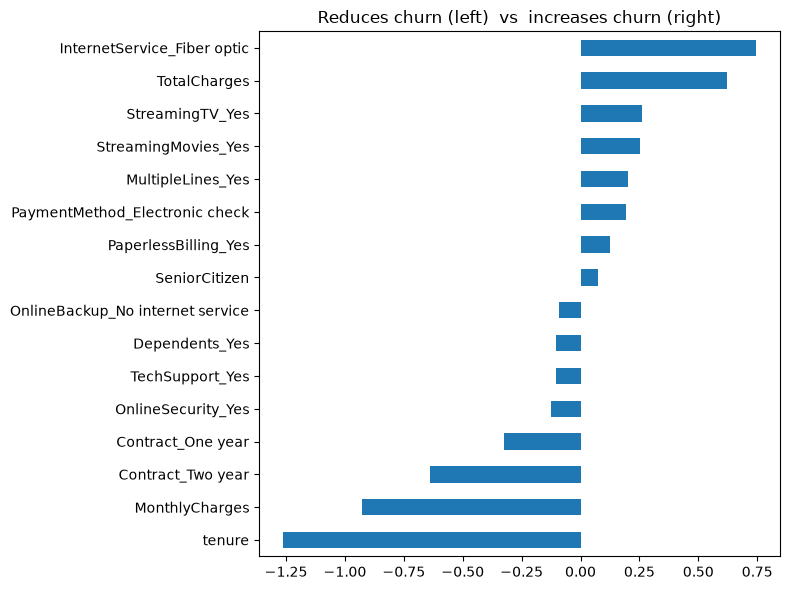

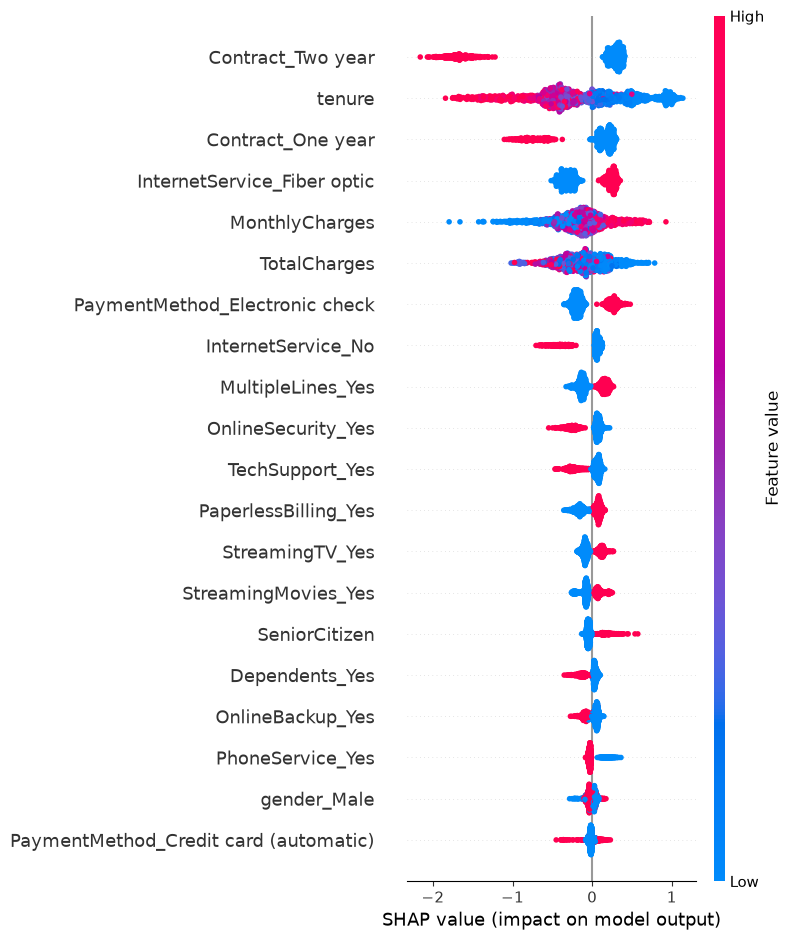

In [62]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import RocCurveDisplay

os.makedirs("images", exist_ok=True)

# 1. ROC curves: all three models compared
fig, ax = plt.subplots(figsize=(7, 5))
for name, m in [("Logistic Regression", lr), ("Random Forest", rf), ("XGBoost", xgb)]:
    RocCurveDisplay.from_estimator(m, x_test, y_test, name=name, ax=ax)
plt.title("Model comparison (ROC)")
plt.tight_layout(); plt.savefig("images/roc_curves.png", dpi=150); plt.show()

# 2. Churn drivers from Logistic Regression (lr is a pipeline, so take its last step)
coef = pd.Series(lr[-1].coef_[0], index=x.columns).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).plot.barh(figsize=(8, 6))
plt.title("Reduces churn (left)  vs  increases churn (right)")
plt.tight_layout(); plt.savefig("images/churn_drivers.png", dpi=150); plt.show()

# 3. SHAP explanation of XGBoost
x_test_num = x_test.astype(float)
shap_values = shap.TreeExplainer(xgb).shap_values(x_test_num)
shap.summary_plot(shap_values, x_test_num, show=False)
plt.tight_layout(); plt.savefig("images/shap_summary.png", dpi=150); plt.show()

From the SHAP chart and your churn drivers chart:

Contract type is the strongest factor. Two-year contracts sharply reduce churn, and one-year contracts also help. Month-to-month customers are the most at risk (42.7% churn, compared with 2.8% on two-year contracts).
New customers leave most. Short tenure strongly increases churn, so the first 12 months is the danger zone.
Fibre optic customers churn more, possibly because of price or service issues.
Paying by electronic check is linked to higher churn, while automatic payments are linked to lower churn.
Add-on support services keep customers. Customers with Online Security and Tech Support churn less.
Higher monthly bills increase churn, as the SHAP chart shows (red dots on the right).

In [63]:
risk = df.loc[x_test.index, ["MonthlyCharges"]].copy()
risk["churn_prob"] = lr_proba
high_risk = risk[risk["churn_prob"] >= 0.7]

print(f"Customers in test set: {len(risk)}")
print(f"High-risk customers (70%+ chance): {len(high_risk)}")
print(f"Their annual revenue at risk: €{high_risk['MonthlyCharges'].sum() * 12:,.0f}")

Customers in test set: 1407
High-risk customers (70%+ chance): 378
Their annual revenue at risk: €356,020
